In [8]:
%pip install graphviz
%pip install torch
import math
import torch
import numpy as np
import random
import matplotlib.pyplot as plt
#Matplotlib is a popular Python library for making graphs and charts from data.
%matplotlib inline
#This is a Jupyter Notebook / Google Colab command that tells Python: Display my Matplotlib graphs directly inside the notebook, below the code cell.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
def f(x):
    return 3*x**2-4*x+5
#Defining a scalar function

In [10]:
f(3)

20

In [11]:
xs=np.arange(-5,5,0.25) #arranges from -5 to 5(excluded) with 0.25 gap (start,stop,step)
print(xs)

[-5.   -4.75 -4.5  -4.25 -4.   -3.75 -3.5  -3.25 -3.   -2.75 -2.5  -2.25
 -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75
  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75  3.    3.25  3.5   3.75
  4.    4.25  4.5   4.75]


[100.      91.6875  83.75    76.1875  69.      62.1875  55.75    49.6875
  44.      38.6875  33.75    29.1875  25.      21.1875  17.75    14.6875
  12.       9.6875   7.75     6.1875   5.       4.1875   3.75     3.6875
   4.       4.6875   5.75     7.1875   9.      11.1875  13.75    16.6875
  20.      23.6875  27.75    32.1875  37.      42.1875  47.75    53.6875]


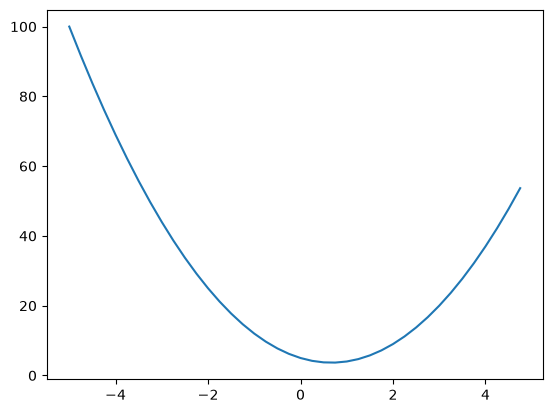

In [12]:
#We can apply function to the entire array at once instead of one at a time, hence improving efficiency
#Example
ys=f(xs)
print(ys)
plt.plot(xs,ys) #(x-axis,y-axis)

In [13]:
class Value:
  
  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"
  
  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')
    
    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    
    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')
    
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
      
    return out
  
  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out
  
  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')
    
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    
    return out
  
  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')
    
    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward
    
    return out
  
  
  def backward(self):
    
    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()



In [14]:
from graphviz import Digraph

def trace(root):
    #builds a set of all nodes and edges in the graph
    nodes,edges= set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"})

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))

        # Create the Value node
        dot.node(
            name=uid,
            label="{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad),
            shape="record"
        )

        # Create the operation node
        if n._op:
            dot.node(
                name=uid + n._op,
                label=n._op
            )

            # Connect operation to result
            dot.edge(
                uid + n._op,
                uid
            )

    # Connect children to operation nodes
    for n1, n2 in edges:
        dot.edge(
            str(id(n1)),
            str(id(n2)) + n2._op
        )

    return dot

  


In [15]:
#L is basically the loss function and we want to implement backprop
#Calculate gradients w.r.t weights and not data(cause data is fixed), then adjust weights to minimise loss function
#So we create a variable 'gradient' inside the value class that maintains the derivative of L w.r.t that value
#we initialise grad at 0.0



In [16]:
#this is a function just to cross check our gradients
def lol():
    h=0.0001
    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L= f*d; L.label='L'
    L1=L.data   #L.data since we want the numerical value

    a=Value(2.0, label='a')
    b=Value(-3.0, label='b')
    c=Value(10.0, label='c')
    e=a*b; e.label='e'
    d=e+c; d.label='d'
    f=Value(-2.0, label='f')
    L= f*d; L.label='L'
    L2=L.data+h

    return ((L2-L1)/h)

lol()
#approximating gradient manually using frst principle
#We copy all these variables inside a function to not mess with the global scope
#We add h to the variable with which we want to calculate gradient

0.9999999999976694

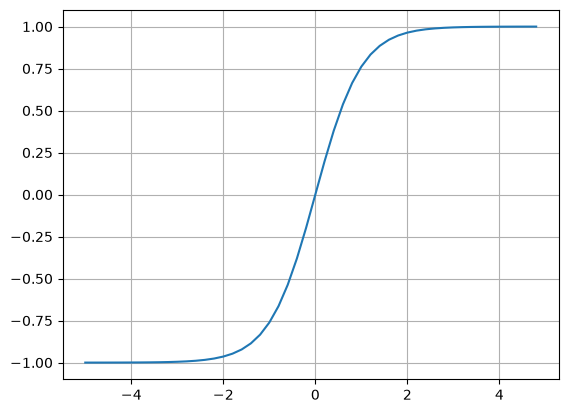

In [17]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid()
#Plotting tanh which is our choice of activation function 'f'. The activation function must be some kind of squashing function

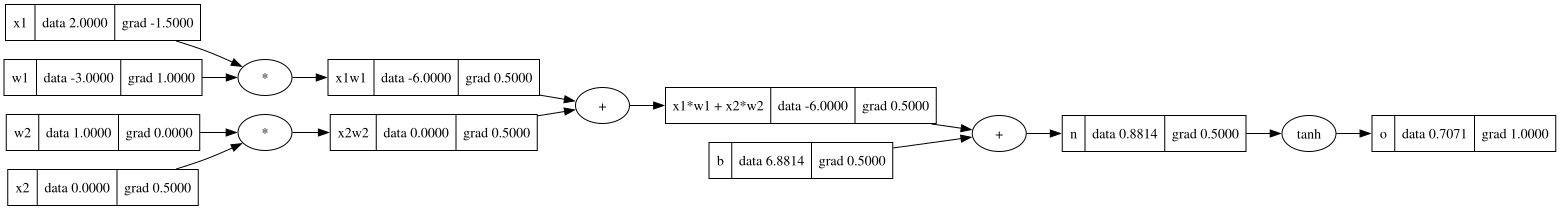

In [18]:
#Building a 2layer neuron

#x1,x2
x1=Value(2.0, label='x1')
x2=Value(0.0, label='x2')
#w1,w2
w1=Value(-3.0, label='w1')
w2=Value(1.0, label='w2')
#bias of the neuron
b=Value(6.8813735870195432, label='b')
#x1w1+x2w2+b
x1w1=x1*w1
x1w1.label='x1w1'
x2w2=x2*w2
x2w2.label='x2w2'

x1w1x2w2=x1w1+x2w2
x1w1x2w2.label='x1*w1 + x2*w2'

n=x1w1x2w2+b
n.label='n'
#The output will be the tanh function applied to n
#However in the value class we have not defined the tanh function so we do that first
o=n.tanh()
o.label='o'
#We can call o._backward directly but scroll back and see that it is initialised at 0 so we first initialise at 1.00
o.backward() #No need fro n manual calls or writing big code every time
draw_dot(o)

In [19]:
# we know dtanhx/dx = 1-tanh^2x so we can easily implement backrpop
#It is extremely tedious to calculate bacprop manually everytime, so now we are going to implement the backprop function
#For backprop and to call the _backward function, everything after it should be complete.
#This ordering of graphs can be done by 'Topolgical Sort'

#o._backward()
#n._backward()
#b.backward would return none although command is not invalid
#x1w1x2w2._backward()
#x1w1._backward()
#x2w2._backward()


In [20]:
#Now we take this code and make it a function so that it is easier to use everytime


In [21]:
#Now we are going to use pytroch

In [22]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item()) #.item strips out the tensor and returns the single element
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())


0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [23]:
#Micrograd is a scalar valued function and pytorch uses tensors (n-dimensional arrays of scalars)
#Now Let's start building out a neural net

In [24]:
class Neuron:
  
  def __init__(self, nin):#nin is number of inputs coming to the neuron
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)] #weight- it creates a random weight between (-1,1)
    self.b = Value(random.uniform(-1,1)) #bias-creates a random bias

#How will we initialise a neuron: n=Neuron(2) 2 reprsents 'nin' implying 2 inputs
  def __call__(self, x):  #call lets u use an object as a function (object- anything which belongs to a class)
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) #this is the dot product wixi+b
    out = act.tanh() #squashing function
    return out
  
  def parameters(self):
    return self.w + [self.b]

#We have defined a single neuron- now we define a layer of neurons

class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs
  
  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP: # MultiLayerPerceptron
  
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x
  
  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]
    

In [25]:
x=[Value(2.0),Value(3.0),Value(-1.0)]  #Very important for value otherwise it won't work, important for 
n=MLP(3, [4,4,1])
n(x)


Value(data=0.9073250899973414)

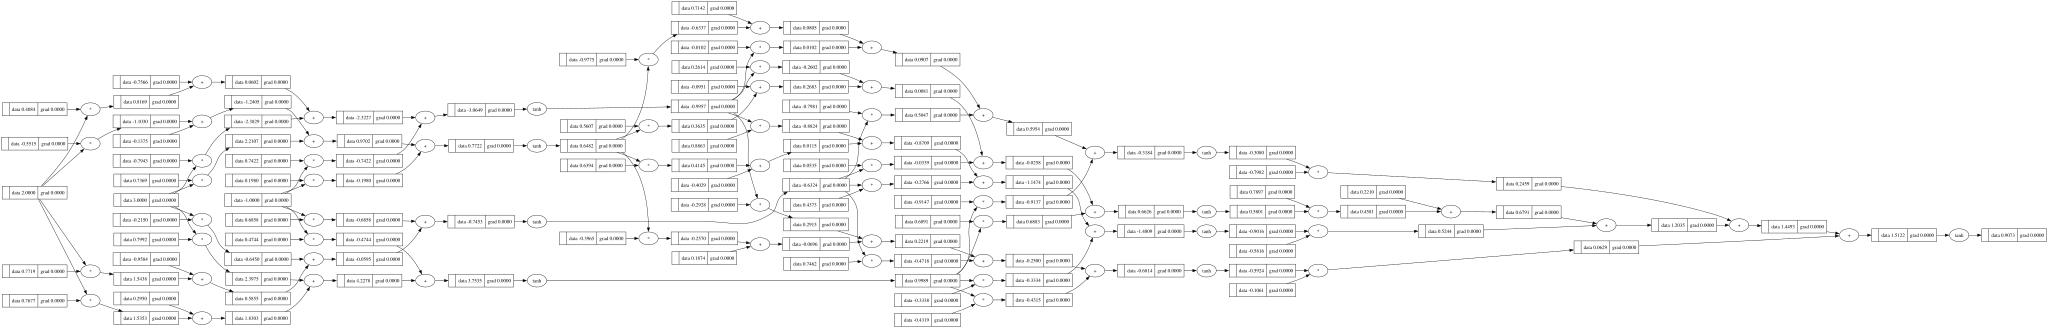

In [26]:
draw_dot(n(x))

In [27]:
xs = [
  [Value(2.0), Value(3.0), Value(-1.0)],
  [Value(3.0), Value(-1.0), Value(0.5)],
  [Value(0.5), Value(1.0), Value(1.0)],
  [Value(1.0), Value(1.0), Value(-1.0)],
]
ys = [Value(1.0), Value(-1.0), Value(-1.0), Value(1.0)] # desired targets

ypred = [n(x) for x in xs] #prediction values
ypred

[Value(data=0.9073250899973414),
 Value(data=0.42525758151413373),
 Value(data=0.9140789566124013),
 Value(data=0.42395080186984524)]

In [28]:
#Now we want the prediction to match the ys or the desired targets
#How do we tune the weights to better predict the desired target
#We calculate the loss- single number which tells us how well the neural net is performing
#We minimise the mean sqaure loss here


In [29]:
for k in range(20):  #Iterating the process of forward and backward pass 20 times
  
  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
  
  # backward pass
  for p in n.parameters():
    p.grad = 0.0
  loss.backward()
  
  # update
  for p in n.parameters():  #nudging all the paramters by a tiny amount and then it proceeds to repeat the process
    p.data += -0.1 * p.grad
  
  print(k, loss.data)

0 6.035478743420331
1 3.4844414003442696
2 2.782460511295055
3 1.2973988412756654
4 0.6068783611075669
5 0.2473467981774714
6 0.08901883606579752
7 0.06653306111852081
8 0.05277395676727413
9 0.04351414641270669
10 0.0368874921830307
11 0.03192869253587957
12 0.02808911877483649
13 0.025034850759595165
14 0.02255155143737531
15 0.020495636723831135
16 0.018767478025016257
17 0.017295878894576025
18 0.016028669732088822
19 0.014926788876488096


In [30]:
ypred

[Value(data=0.9455566864315476),
 Value(data=-0.9882705076305416),
 Value(data=-0.9194006773994617),
 Value(data=0.9270008035026108)]